# WMC Practical Examination — Statement #10
## Identification and Analysis of Nearby Wi-Fi Networks (WiFi Analyzer app)

**Problem statement.** Using the WiFi Analyzer (open-source) application by VREM Software Development on an Android smartphone, scan and analyse nearby Wi-Fi networks.
1. Record the details of at least five visible Wi-Fi networks in a table with the following columns: (i) SSID, (ii) BSSID, (iii) RSSI (dBm), (iv) Channel number, (v) Frequency band (GHz).
2. Identify the networks with the strongest and weakest received signal strengths based on their RSSI values.

---
**Aim:** To scan the surrounding wireless environment with an Android Wi-Fi analyser, tabulate the parameters of nearby access points and compare their received signal strengths.

**Apparatus:** Android smartphone with Location + Wi-Fi ON · *WiFi Analyzer (open-source)* by VREM Software Development (F-Droid / Play Store) · this notebook for tabulation and analysis.

## Theory (brief)
- **SSID** – the network name broadcast by an access point. **BSSID** – the MAC address of the access point's radio (one physical AP can broadcast several BSSIDs, e.g. one per band).
- **RSSI** (Received Signal Strength Indicator) – received power in **dBm**; it is always negative and **closer to 0 means stronger**. Every −3 dB halves the power and every −10 dB is a tenth of the power.

| RSSI (dBm) | Quality |
|---|---|
| ≥ −50 | Excellent |
| −50 to −60 | Good |
| −60 to −70 | Fair |
| −70 to −80 | Weak |
| < −80 | Very weak / unusable |

- **Channel & band** – 2.4 GHz band: channels 1–13 (centre = 2407 + 5·ch MHz, only 1, 6, 11 are non-overlapping). 5 GHz band: channels 36–165 (centre = 5000 + 5·ch MHz), more channels, less interference, shorter range.

## Procedure
1. Turn ON Wi-Fi and Location on the phone; open **WiFi Analyzer** and allow the location permission.
2. Open the **Access Points** view (menu → *Access Points*). Each entry shows SSID, BSSID (MAC), RSSI in dBm, channel and frequency (MHz).
3. Note at least five networks (pause the scan with the ⏸ button so values do not keep changing, or take a screenshot).
4. Enter the values in the ✏️ cell below and run the notebook.

> ⚠️ **The readings currently in this notebook are SAMPLE values** so that every table, graph and conclusion is visible.
> To use your own: open the cell marked **✏️ ENTER YOUR READINGS**, replace the values with what you recorded, set `SAMPLE_DATA = False`, then **Run All**. Every table, graph and conclusion below updates automatically.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ✏️ ENTER YOUR READINGS  (SSID, BSSID, RSSI in dBm, channel, frequency in MHz as shown in the app)
SAMPLE_DATA = True
networks = [
    ("Lab-WiFi-5G",        "a4:2b:b0:6e:10:21", -41,  36, 5180),
    ("Lab-WiFi",           "a4:2b:b0:6e:10:20", -48,   6, 2437),
    ("JioFiber-7C1D",      "c8:3a:35:7c:1d:02", -57,  11, 2462),
    ("Airtel_Xstream_4F2A","74:da:88:4f:2a:91", -64,   1, 2412),
    ("Library_Guest",      "00:1e:58:b2:77:40", -71,   6, 2437),
    ("TP-Link_3B90",       "50:c7:bf:3b:90:aa", -79,   9, 2452),
    ("Redmi Note Hotspot", "d2:84:1f:09:6c:13", -86,   1, 2412),
]

df = pd.DataFrame(networks, columns=["SSID", "BSSID", "RSSI (dBm)", "Channel", "Frequency (MHz)"])
df["Frequency band (GHz)"] = df["Frequency (MHz)"].apply(lambda f: 2.4 if f < 3000 else (5 if f < 5925 else 6))
print(f"{len(df)} networks entered" + ("  (SAMPLE DATA)" if SAMPLE_DATA else ""))
if SAMPLE_DATA:
    display(Markdown("<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'>"
                     "<b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>"))

7 networks entered  (SAMPLE DATA)


<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'><b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>

In [2]:
def quality(r):
    if r >= -50: return "Excellent"
    if r >= -60: return "Good"
    if r >= -70: return "Fair"
    if r >= -80: return "Weak"
    return "Very weak"

df["Signal quality"] = df["RSSI (dBm)"].apply(quality)
strong = df.loc[df["RSSI (dBm)"].idxmax()]
weak = df.loc[df["RSSI (dBm)"].idxmin()]

table = df[["SSID", "BSSID", "RSSI (dBm)", "Channel", "Frequency band (GHz)", "Signal quality"]].copy()
table.index = range(1, len(table) + 1); table.index.name = "Sr. No."

def hl(row):
    if row["SSID"] == strong["SSID"] and row["BSSID"] == strong["BSSID"]:
        return ["background-color:#c6f6d5;font-weight:bold"] * len(row)
    if row["SSID"] == weak["SSID"] and row["BSSID"] == weak["BSSID"]:
        return ["background-color:#fed7d7;font-weight:bold"] * len(row)
    return [""] * len(row)

display(Markdown("### Observation table (green = strongest, red = weakest)"))
display(table.style.apply(hl, axis=1).format({"Frequency band (GHz)": "{:g}"}))

### Observation table (green = strongest, red = weakest)

,SSID,BSSID,RSSI (dBm),Channel,Frequency band (GHz),Signal quality
Sr. No.,,,,,,
1,Lab-WiFi-5G,a4:2b:b0:6e:10:21,-41,36,5,Excellent
2,Lab-WiFi,a4:2b:b0:6e:10:20,-48,6,2.4,Excellent
3,JioFiber-7C1D,c8:3a:35:7c:1d:02,-57,11,2.4,Good
4,Airtel_Xstream_4F2A,74:da:88:4f:2a:91,-64,1,2.4,Fair
5,Library_Guest,00:1e:58:b2:77:40,-71,6,2.4,Weak
6,TP-Link_3B90,50:c7:bf:3b:90:aa,-79,9,2.4,Weak
7,Redmi Note Hotspot,d2:84:1f:09:6c:13,-86,1,2.4,Very weak


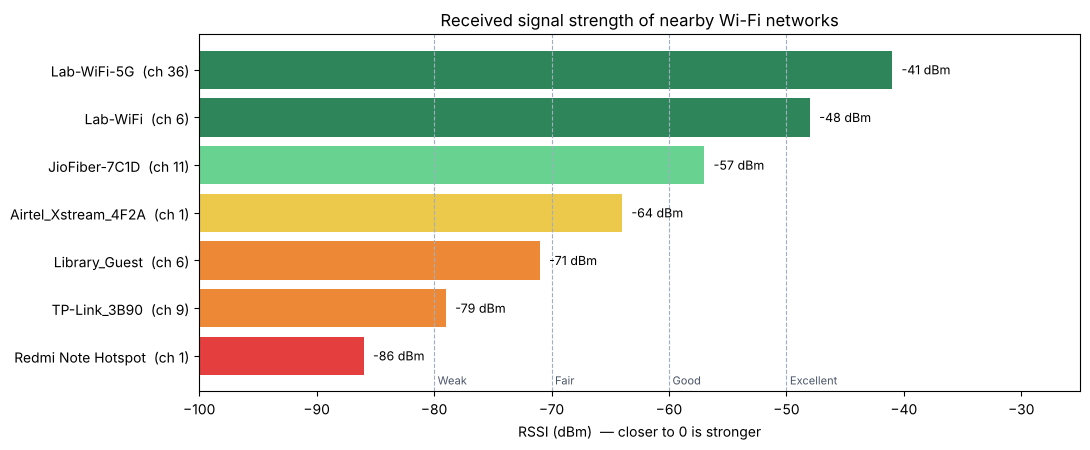

In [3]:
d = df.sort_values("RSSI (dBm)", ascending=False)
colors = {"Excellent": "#2f855a", "Good": "#68d391", "Fair": "#ecc94b", "Weak": "#ed8936", "Very weak": "#e53e3e"}
fig, ax = plt.subplots(figsize=(11, 4.6))
bars = ax.barh([f"{s}  (ch {c})" for s, c in zip(d["SSID"], d["Channel"])], d["RSSI (dBm)"] + 100,
               left=-100, color=[colors[q] for q in d["Signal quality"]])
for b, r in zip(bars, d["RSSI (dBm)"]):
    ax.text(r + 0.8, b.get_y() + b.get_height() / 2, f"{r} dBm", va="center", fontsize=9)
for x, lab in [(-50, "Excellent"), (-60, "Good"), (-70, "Fair"), (-80, "Weak")]:
    ax.axvline(x, color="#a0aec0", ls="--", lw=0.8); ax.text(x + 0.3, len(d) - 0.4, lab, fontsize=8, color="#4a5568")
ax.invert_yaxis(); ax.set_xlim(-100, -25); ax.set_xlabel("RSSI (dBm)  — closer to 0 is stronger")
ax.set_title("Received signal strength of nearby Wi-Fi networks")
plt.tight_layout(); plt.show()

In [4]:
diff = strong["RSSI (dBm)"] - weak["RSSI (dBm)"]
ratio = 10 ** (diff / 10)
n24 = (df["Frequency band (GHz)"] == 2.4).sum(); n5 = (df["Frequency band (GHz)"] == 5).sum()
display(Markdown(f"""### Strongest and weakest networks
| | SSID | BSSID | RSSI | Channel | Band | Quality |
|---|---|---|---|---|---|---|
| **Strongest** | {strong['SSID']} | `{strong['BSSID']}` | **{strong['RSSI (dBm)']} dBm** | {strong['Channel']} | {strong['Frequency band (GHz)']:g} GHz | {strong['Signal quality']} |
| **Weakest** | {weak['SSID']} | `{weak['BSSID']}` | **{weak['RSSI (dBm)']} dBm** | {weak['Channel']} | {weak['Frequency band (GHz)']:g} GHz | {weak['Signal quality']} |

The strongest signal is **{diff} dB** above the weakest, i.e. about **{ratio:,.0f} times more received power**.
Networks seen: **{n24} on 2.4 GHz** and **{n5} on 5 GHz**."""))

### Strongest and weakest networks
| | SSID | BSSID | RSSI | Channel | Band | Quality |
|---|---|---|---|---|---|---|
| **Strongest** | Lab-WiFi-5G | `a4:2b:b0:6e:10:21` | **-41 dBm** | 36 | 5 GHz | Excellent |
| **Weakest** | Redmi Note Hotspot | `d2:84:1f:09:6c:13` | **-86 dBm** | 1 | 2.4 GHz | Very weak |

The strongest signal is **45 dB** above the weakest, i.e. about **31,623 times more received power**.
Networks seen: **6 on 2.4 GHz** and **1 on 5 GHz**.

## Result & Conclusion
At least five nearby Wi-Fi networks were identified with their SSID, BSSID, RSSI, channel and frequency band (table above). The network with the highest (least negative) RSSI is the **strongest** and the one with the most negative RSSI is the **weakest**; both are highlighted and stated in the summary above.

RSSI depends mainly on the **distance** to the access point, **obstacles** (walls, floors, people) and the **frequency band** — 5 GHz signals usually show lower RSSI than 2.4 GHz at the same distance because they attenuate faster, but they offer more non-overlapping channels. Networks above about −67 dBm are suitable for reliable connections, while those below −80 dBm are close to the noise floor and practically unusable. Wi-Fi analyser apps therefore help in choosing the best network/access point and in planning AP placement.